# The capital plan: pre-provision revenue, the CET1 path, the EBA static balance sheet and the Chilean capital stack

**Question:** Under the Federal Reserve severely adverse scenario, does Banco Andino keep its effective equity above the legal
minimum in each of the three years, and above its own internal capital target?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 04 of this topic (the scenarios and the loss rates they imply)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- build the headline CET1 path of a stress as the starting CET1 less the cumulated stressed losses, and say why no revenue is
  invented in it;
- add the labelled pre-provision net revenue row from two stated ratios and see how far it lifts the ratio;
- build the internal capital target and the legal minimum of the Chilean IAPE framework, and see the engine refuse a
  requirement above the 4 percent cap and an own estimate below the requirement;
- run the three cases of the capital plan on a static balance sheet, and read the difference between holding the legal minimum
  and holding the bank's own target;
- apply the EBA stage 3 rule, plant a violation and watch the engine name it, and rebuild the 34 rows of the Annex 3 form.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. 
This notebook also reads one constants file of the product's pipeline, `data-pipeline/pipeline/cases/c18/params.py` (the map from the six C07 segments to the three loan classes). The pipeline is a set of scripts and not a package, so the notebook loads that one file by its path with the standard library: one source for the map, never a copy. The file has no dependency.

The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Imports, versions and the readers; the pipeline folder goes on the path because the pipeline is never installed
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.stress import capital
from riskvalidation.validation import stress as stress_tests

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c18 import params as c18_params


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

This notebook reads the capital side of **C18** (Banco Andino).

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 1.0.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` and `fed-2026-severely-adverse.json` (`outputs.capital_start`, `losses`, `internal_capital_target`, `headline_cet1`, `capital_plan`, `p2g_proxy`, `annex3`), the models document `models-banco-andino.json` (the Chilean stack, the EBA rules by paragraph), `reverse-stress.json` (the failure-point stack), and, for the static balance sheet, the stage balances and the segment parameters of the provisions case C07 (`data/derived/C07/base.json` and `models-banco-andino.json`) and the segment-to-class map of `data-pipeline/pipeline/cases/c18/params.py`.
- **Banco Andino's capital is an anchor, not a balance sheet.** CET1 is the Tier 1 proxy of the interest-rate case C15; the risk-weighted assets (RWA) are that proxy over the 11.0 percent CET1 anchor, split between credit, market and operational risk by the mix of a large Chilean bank's 2025 Form 20-F (ratios only, because the filing is derived-only). The part of the effective equity above CET1 is carried as Tier 2 and AT1 is nil, an assumption **UNVERIFIED** in the sources and labelled so in the document. Money is in CLP millions and shares are shares of RWA.

In [2]:
# The baseline and severely adverse capital documents, the models document and the jump-off capital
baseline = read_json("C18/baseline.json")["outputs"]
fed_doc = read_json("C18/fed-2026-severely-adverse.json")
fed = fed_doc["outputs"]
models = read_json("C18/models-banco-andino.json")["fit"]
start = fed["capital_start"]
YEARS = ["1", "2", "3"]
print("jump-off", fed["bank"]["as_of"])
print("RWA", round(start["rwa_clp_m"], 1), "CET1", round(start["cet1_clp_m"], 1))
print("CET1 ratio and effective-equity ratio", start["cet1_ratio"], round(start["pe_ratio"], 6))

jump-off 2026-08-31
RWA 7492853.0 CET1 824213.8
CET1 ratio and effective-equity ratio 0.11 0.168938


## Method

### Step 1: the headline path, CET1 less the losses

The **headline** CET1 path of the case is the **loss-only depletion**: CET1 at the jump-off less the cumulated stressed losses of the years so far, with no revenue invented,

$$\mathrm{CET1}_y = \mathrm{CET1}_0 - \sum_{s \le y} L_s, \qquad y = 1, 2, 3.$$

The loss of a year is the sum of the credit loss of notebook 04 and the expected losses of the other risks: market and operational risk have no position book or macro map in the case, so each carries its annual expected loss in every scenario and the stressed loss is a floor. The IRRBB loss is nil because an economic-value change is not a profit-and-loss item of the banking book; the rate path acts on net interest income instead (step 2). `cet1_path_loss_only(cet1_0, losses)` computes the path.

The next cell reads the losses of the severely adverse scenario, builds the path with `cet1_path_loss_only` and draws the
stressed loss of each year, by credit and operational risk, with the CET1 ratio that results.

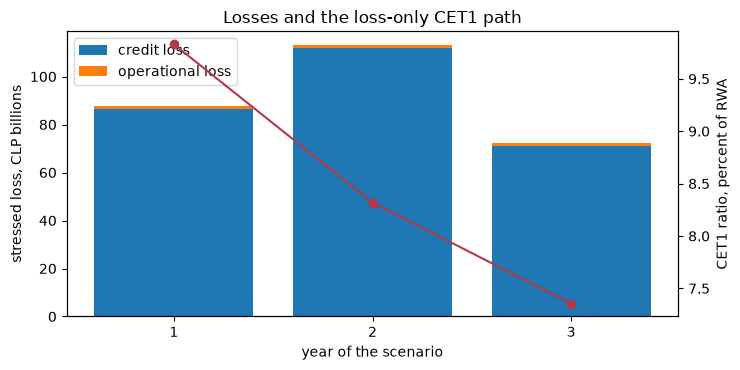

stressed losses, CLP millions [87706, 113174, 72193]
CET1 path, CLP millions [736507.7 623333.4 551140.8]
CET1 ratio, percent of RWA [9.83 8.32 7.36]
CET1 ratio at the jump-off, percent 11.0


In [3]:
# The loss-only CET1 path of the severely adverse scenario and the losses behind it
loss_rows = fed["losses"]["scenario_losses"]
losses = [row["total"] for row in loss_rows]
path = capital.cet1_path_loss_only(start["cet1_clp_m"], losses)
ratio = path / start["rwa_clp_m"]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bottom = np.zeros(3)
for part, label in (("credit", "credit loss"), ("operational", "operational loss")):
    values = np.array([row[part] for row in loss_rows]) / 1e3
    ax.bar(YEARS, values, bottom=bottom, label=label)
    bottom += values
ax.set_xlabel("year of the scenario")
ax.set_ylabel("stressed loss, CLP billions")
ax.legend(loc="upper left")
twin = ax.twinx()
twin.plot(YEARS, ratio * 100, "o-", color="#b23a48")
twin.set_ylabel("CET1 ratio, percent of RWA")
ax.set_title("Losses and the loss-only CET1 path")
fig.tight_layout()
plt.show()
print("stressed losses, CLP millions", [round(v) for v in losses])
print("CET1 path, CLP millions", np.round(path, 1))
print("CET1 ratio, percent of RWA", np.round(ratio * 100, 2))
print("CET1 ratio at the jump-off, percent", round(start["cet1_ratio"] * 100, 2))

The bars are almost all credit loss, CLP 86,519, 111,987 and 71,005 million, because market and operational risk carry only
their expected loss in every scenario, 1,188 million for operational risk and none for market, so the stressed loss is a floor.
The red line is the CET1 ratio that results: 11.00 percent of RWA at the jump-off falls to 9.83, 8.32 and 7.36 percent. Nothing
is added back, which is deliberate, because a headline that counted revenue the bank has not earned would flatter the ratio.

### Step 2: the labelled PPNR row

A bank earns while it loses. The case adds a **labelled row** with pre-provision net revenue, never the headline. The net interest income (NII) of each year follows the scenario's rate path through the interest-rate engine of topic 09 on the C15 book; the fee income and the operating cost are two stated constant ratios, assumptions of the case and not Banco Andino or CMF figures:

$$\text{fees} = r_{\text{fee}}\cdot\mathrm{NII},\qquad \text{cost} = r_{\text{cost}}\,(\mathrm{NII} + \text{fees}),\qquad \mathrm{PPNR} = \mathrm{NII} + \text{fees} - \text{cost},$$

with $r_{\text{fee}} = 0.25$ and $r_{\text{cost}} = 0.55$. The Federal Reserve documents no PPNR model in the dossiers; its efficiency-ratio element is only the precedent for a cost ratio. `ppnr_row(nii, fee_ratio, cost_ratio)` computes the row.

The next cell calls `ppnr_row` for each year with the committed net interest income and the two stated ratios, adds the
cumulated PPNR to the loss-only path and draws the components of the row next to the CET1 ratio with and without it.

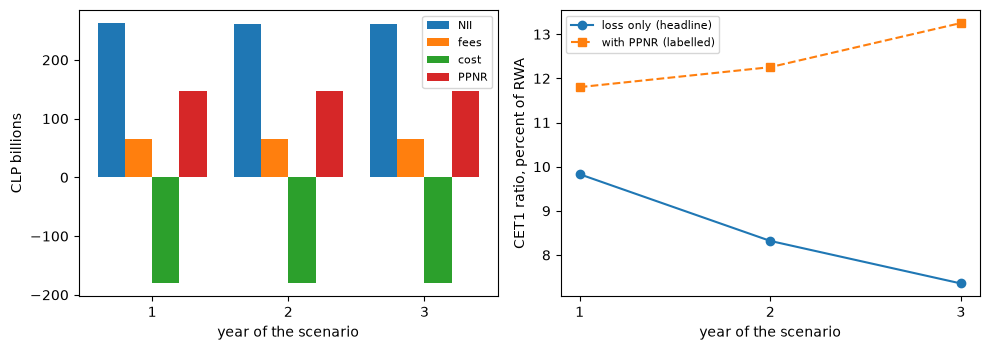

NII, fees, cost, PPNR of year 1 [262778, 65695, 180660, 147813]
PPNR by year [147813, 147070, 147070]
CET1 ratio with PPNR [11.8  12.25 13.25]


In [4]:
# The labelled PPNR row of each year from the committed NII and the two stated ratios, and the CET1 with PPNR
ppnr = fed["headline_cet1"]["ppnr"]
fee_ratio, cost_ratio = ppnr["fee_ratio"]["value"], ppnr["cost_ratio"]["value"]
rows = [capital.ppnr_row(r["nii_clp_m"], fee_ratio, cost_ratio) for r in ppnr["rows"]]
with_ppnr = path + np.cumsum([r.ppnr for r in rows])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
width = 0.2
for k, (label, values) in enumerate((("NII", [r.nii for r in rows]), ("fees", [r.fee_income for r in rows]),
                                     ("cost", [-r.operating_cost for r in rows]), ("PPNR", [r.ppnr for r in rows]))):
    axes[0].bar(np.arange(3) + (k - 1.5) * width, np.array(values) / 1e3, width=width, label=label)
axes[0].set_xticks(np.arange(3))
axes[0].set_xticklabels(YEARS)
axes[0].set_ylabel("CLP billions")
axes[0].legend(fontsize=8)
axes[1].plot(YEARS, ratio * 100, "o-", label="loss only (headline)")
axes[1].plot(YEARS, with_ppnr / start["rwa_clp_m"] * 100, "s--", label="with PPNR (labelled)")
axes[1].set_ylabel("CET1 ratio, percent of RWA")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("year of the scenario")
fig.tight_layout()
plt.show()
year1 = (rows[0].nii, rows[0].fee_income, rows[0].operating_cost, rows[0].ppnr)
print("NII, fees, cost, PPNR of year 1", [round(v) for v in year1])
print("PPNR by year", [round(r.ppnr) for r in rows])
print("CET1 ratio with PPNR", np.round(with_ppnr / start["rwa_clp_m"] * 100, 2))

The labelled row adds about CLP 147,000 million a year (147,813, then 147,070 twice), which is NII of 262,778 million plus 25
percent in fees less 55 percent of the total in costs. It lifts the CET1 ratio to 11.80, 12.25 and 13.25 percent, higher than
the starting 11.00, and that is why the row is a label and not the headline: a stressed bank that ends above where it started
rests its answer on two ratios the case assumes and on a rate path, neither of them a prediction. The right panel makes the
distance between the two readings of the same scenario visible.

### Step 3: the internal capital target and the legal minimum

Under Chile's IAPE framework (CMF RAN 21-13, Chapter 21-13 section I; dossier 03) a bank sets an **internal target** for effective equity over RWA,

$$\mathrm{OI} \;\ge\; 8\% + c_{\mathrm{DSIB}} + c_{P2} + c_{\mathrm{CCoB}} + c_{\mathrm{CCyB}} + c_d,$$

the 8 percent minimum plus the systemic-bank buffer, the bank's own Pillar 2 estimate, the conservation and countercyclical buffers and a voluntary stress buffer $c_d$ (which may be zero). The Pillar 2 term has two distinct things in it: the **article 66 quinquies requirement** $p2r$, which the CMF sets and which the law caps at **4 percent of RWA**, and the bank's own estimate $c_{P2} \ge p2r$, which has no cap. The engine's `internal_capital_target` enforces both facts. The legal minimum against which the stress is tested is $8\% + c_{\mathrm{DSIB}} + p2r$.

The next cell builds the target with `internal_capital_target` from the committed components and draws it as a stack beside
the legal minimum; it then offers the engine a requirement above the cap and an own estimate below the requirement, and
computes `chilean_cet1_stack`, the minimum CET1 over RWA of the legal stack, with the share that the reverse stress of
notebook 06 uses.

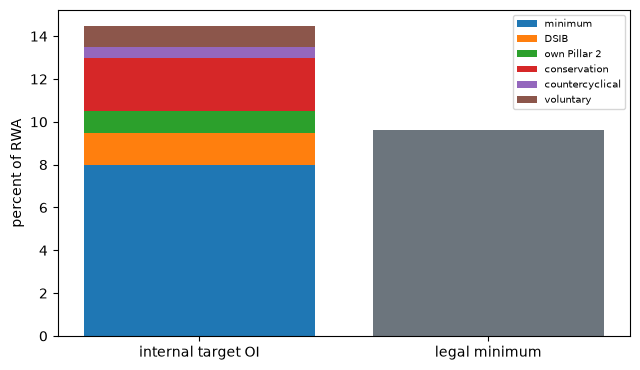

percent of RWA: OI 14.5 legal minimum 9.625
p2r (art. 66 quinquies), percent 0.125
p2r above the 4 percent cap : refused
own estimate below p2r : refused
CET1 stack with the reverse stress share, percent 9.0625


In [5]:
# The internal target and the legal minimum from the committed components, the two refusals and the CET1 stack
target = fed["internal_capital_target"]
stack = models["bank_anchors"]["chilean_stack"]
own, voluntary = target["c_p2"]["value"], target["c_d"]["value"]
buffers = (target["c_dsib"], own, target["c_ccob"], target["c_ccyb"], voluntary)
oi = capital.internal_capital_target(*buffers, p2r=stack["p2r"])
legal_minimum = oi.min_pe + oi.c_dsib + oi.p2r
parts = [("minimum", oi.min_pe), ("DSIB", oi.c_dsib), ("own Pillar 2", oi.c_p2), ("conservation", oi.c_ccob),
         ("countercyclical", oi.c_ccyb), ("voluntary", oi.c_d)]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
bottom = 0.0
for label, value in parts:
    ax.bar("internal target OI", value * 100, bottom=bottom * 100, label=label)
    bottom += value
ax.bar("legal minimum", legal_minimum * 100, color="#6c757d")
ax.set_ylabel("percent of RWA")
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
plt.show()
print("percent of RWA: OI", round(oi.oi * 100, 3), "legal minimum", round(legal_minimum * 100, 3))
print("p2r (art. 66 quinquies), percent", round(oi.p2r * 100, 3))
for why, p2r, c_p2 in (("p2r above the 4 percent cap", 0.05, 0.05), ("own estimate below p2r", 0.02, 0.01)):
    try:
        capital.internal_capital_target(buffers[0], c_p2, *buffers[2:], p2r=p2r)
    except ValueError:
        print(why, ": refused")
reverse = read_json("C18/reverse-stress.json")["outputs"]["failure_point"]["stack"]
cet1_stack = capital.chilean_cet1_stack(reverse["c_ccyb"], reverse["c_dsib"], reverse["p2_cet1"]["value"])
print("CET1 stack with the reverse stress share, percent", round(cet1_stack * 100, 4))

The internal target stacks to 14.5 percent of RWA: the 8 percent minimum, 1.5 for the systemic-bank buffer, 1.0 for the bank's
own Pillar 2 estimate, 2.5 for conservation, 0.5 countercyclical and a voluntary stress buffer of 1.0. The legal minimum, the
grey bar, is far lower, 9.625 percent, because it keeps only the minimum, the systemic buffer and the article 66 quinquies
requirement of 0.125 percent, which is what the CMF sets and the law caps at 4. The engine refuses both mistakes, a
requirement above the cap and an estimate below the requirement. The CET1 stack of the reverse stress comes out at 9.0625.

### Step 4: the three cases of the plan

`capital_plan(rwa, cet1_0, at1, t2, base_cet1, stress_losses, mitigation_effects, oi, legal_minimum)` returns, for three years, the three cases of the IAPE projection (dossier 03):

- **base:** CET1 from the caller's baseline path (the baseline scenario's CET1 with its PPNR), tested against the internal target OI;
- **stress without mitigation:** the loss-only path of step 1, tested against the legal minimum;
- **stress with mitigation:** the same path plus the cumulated mitigation actions.

Under the **static balance sheet** of the EBA rules the RWA is the same every year, AT1 and Tier 2 stay at their jump-off values, and no capital measure is allowed after the reference date. The sources name no mitigation action, so the case assumes none (the mitigation case equals the unmitigated one and row 10.2 of Annex 3 is not applicable). The headroom of a year is the effective-equity ratio less the requirement, and the deficit is $\max(0, \text{requirement}\cdot\mathrm{RWA} - \mathrm{PE})$.

The base path is the baseline scenario's CET1 with PPNR, which the next cell rebuilds from the baseline document's own losses and PPNR rows before calling the engine. It draws the effective-equity ratio of the three cases against the two requirements and prints the stressed ratio against the **internal target**, not only the legal minimum.

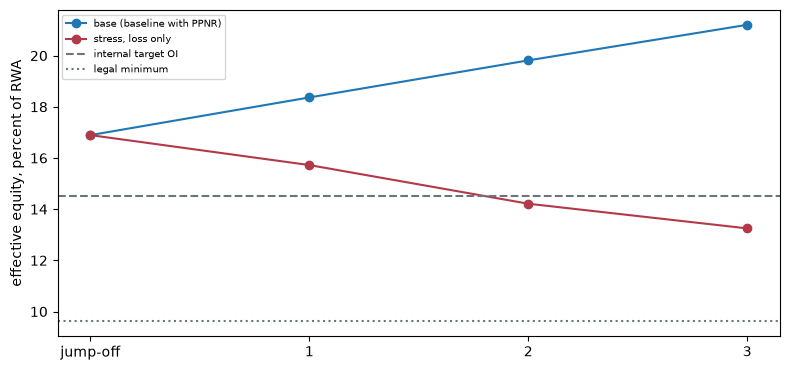

base                       [18.37, 19.81, 21.2] deficit [0, 0, 0]
stress-without-mitigation  [15.72, 14.21, 13.25] deficit [0, 0, 0]
stress-with-mitigation     [15.72, 14.21, 13.25] deficit [0, 0, 0]
stress, equity less the internal target, points [1.22, -0.29, -1.25]


In [6]:
# Rebuild the base CET1 path, run the three cases of the plan and draw the effective-equity ratios
base_rows = baseline["headline_cet1"]["ppnr"]["rows"]
base_losses = [row["total"] for row in baseline["losses"]["scenario_losses"]]
base_cet1 = start["cet1_clp_m"] + np.cumsum([r["ppnr_clp_m"] - loss for r, loss in zip(base_rows, base_losses)])
plan = capital.capital_plan(start["rwa_clp_m"], start["cet1_clp_m"], start["at1_clp_m"], start["t2_clp_m"],
                            base_cet1, losses, [0.0, 0.0, 0.0], oi.oi, legal_minimum)
stress = plan["stress-without-mitigation"]
x = np.arange(0, 4)
fig, ax = plt.subplots(figsize=(8, 3.8))
pe_base = [start["pe_ratio"] * 100] + [y.pe_pct * 100 for y in plan["base"]]
pe_stress = [start["pe_ratio"] * 100] + [y.pe_pct * 100 for y in stress]
ax.plot(x, pe_base, "o-", label="base (baseline with PPNR)")
ax.plot(x, pe_stress, "o-", color="#b23a48", label="stress, loss only")
ax.axhline(oi.oi * 100, color="#6c757d", linestyle="--", label="internal target OI")
ax.axhline(legal_minimum * 100, color="#6c757d", linestyle=":", label="legal minimum")
ax.set_xticks(x)
ax.set_xticklabels(["jump-off"] + [f"{k}" for k in (1, 2, 3)])
ax.set_ylabel("effective equity, percent of RWA")
ax.legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()
for case, years in plan.items():
    print(f"{case:26s}", [round(y.pe_pct * 100, 2) for y in years], "deficit", [round(y.deficit) for y in years])
print("stress, equity less the internal target, points",
      [round((y.pe_pct - oi.oi) * 100, 2) for y in stress])

The legal minimum is held in every year of the severely adverse scenario, with the stressed effective-equity ratio at 15.72,
14.21 and 13.25 percent against 9.625 and a deficit of zero. The internal target is another matter: the ratio is 1.22 points
above the 14.5 percent target in the first year and 0.29 and 1.25 points below it in the second and third. **Holding the legal
minimum and missing the bank's own target are two different findings**, one of solvency under the regulation and one of
whether the bank's risk appetite survives the scenario. The mitigation case equals the unmitigated one because the sources
name no action, and the base case stays 3.9 to 6.7 points above the target.

### Step 5: the EBA static balance-sheet rules

The EBA 2025 methodological note (paragraphs 33, 34 and 90 to 92) fixes the balance sheet during the stress: the total exposure
is constant, maturing exposures are replaced by similar ones, **new stage 3 exposures move into the stock of stage 3 and nothing
leaves it** (no cures, charge-offs or write-offs within the three years), and impairments are computed on a constant balance
sheet. `eba_static_balance_sheet(stage_balances, new_s3_flows)` applies the stage 3 rule: each period's new stage 3 exposure
leaves stages 1 and 2 pro rata to their balances and joins stage 3. The first of the next two cells builds the twelve quarterly
flows of new stage 3 exposure, the quarterly charge-off amount over the loss given default of the class, from the satellite
rates and the provisions case C07, with the segment-to-class map of the pipeline's `params.py`.

In [7]:
# The segment-to-class map of the pipeline, the stage balances of C07 and the quarterly new stage 3 flows
c07 = read_json("C07/base.json")["outputs"]
c07_fit = {s["segment_id"]: s for s in read_json("C07/models-banco-andino.json")["fit"]["ifrs9"]["segments"]}
exposure, lgd_weighted = {}, {}
for segment in c07["portfolio"]["segments"]:
    klass = c18_params.SEGMENT_CLASS[segment["segment_id"]]
    amount = segment["gross_exposure"] / 1e6
    exposure[klass] = exposure.get(klass, 0.0) + amount
    lgd_weighted[klass] = lgd_weighted.get(klass, 0.0) + amount * c07_fit[segment["segment_id"]]["lgd"]
class_lgd = {k: lgd_weighted[k] / exposure[k] for k in exposure}
classes = fed["satellites"]["banco_andino_classes"]
class_rates = {k["banco_andino_class"]: np.array([q["rate"] for q in k["quarters"]]) for k in classes}
flows = np.array([sum(exposure[k] * max(class_rates[k][q], 0.0) / 4.0 / class_lgd[k] for k in exposure)
                  for q in range(12)])
summary = c07["ifrs9_detail"]["stage_summary"]
stage_balances = np.array([row["gross_carrying_amount"] / 1e6 for row in summary][:3])
print("stage balances 1, 2, 3 at the jump-off", np.round(stage_balances, 0))
print("new stage 3 exposure, first 4 quarters", np.round(flows[:4], 0))
print("total over 12 quarters", round(float(flows.sum()), 0))

stage balances 1, 2, 3 at the jump-off [5420854.  437917.  141229.]
new stage 3 exposure, first 4 quarters [ 50861.  79665. 101175. 116751.]
total over 12 quarters 1131441.0


The next cell applies the rule with `eba_static_balance_sheet` to those twelve flows and draws the three stage balances quarter
by quarter, then runs the engine's `static_balance_sheet_rules` test on the result.

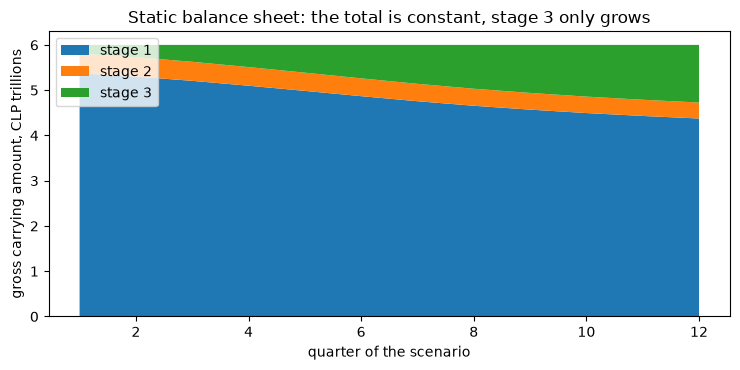

after quarter 1 [5373795.  434116.  192090.] after quarter 12 [4373983.  353347. 1272670.]
engine test violated rules [] periods 12


In [8]:
# Apply the stage 3 rule to the twelve flows, draw the stage balances and run the engine's test
balances = capital.eba_static_balance_sheet(stage_balances, flows)
tolerance = 1e-9 * float(stage_balances.sum())
result = stress_tests.static_balance_sheet_rules(balances, tolerance=tolerance)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.stackplot(np.arange(1, 13), balances.T / 1e6, labels=["stage 1", "stage 2", "stage 3"])
ax.set_xlabel("quarter of the scenario")
ax.set_ylabel("gross carrying amount, CLP trillions")
ax.set_title("Static balance sheet: the total is constant, stage 3 only grows")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
print("after quarter 1", np.round(balances[0], 0), "after quarter 12", np.round(balances[-1], 0))
print("engine test", "violated rules", result.extras["violated"], "periods", result.n)

The three bands always add up to the same height, the constant total, while the stage 3 band at the bottom grows from CLP
141,229 million at the jump-off to 1,272,670 million after twelve quarters, the sum of CLP 1,131,441 million of new stage 3
exposure. Stages 1 and 2 shrink pro rata to pay for it. The engine's test finds no violated rule over the twelve periods. A
test earns its place by failing when it should, which the next cell checks by planting two violations on copies of the
balances.

The rule holds on the committed path. A test earns its place by failing when it should, so the next cell plants two violations in a copy of the balances, a cure (stage 3 falls in the last quarter) and a change of the total (a stage 1 balance is increased), and the engine names each broken rule.

In [9]:
# Plant a cure and a change of the total in copies of the balances and let the engine name the broken rules
cured = balances.copy()
cured[-1] = cured[-1] + np.array([cured[-1, 2] * 0.1, 0.0, -cured[-1, 2] * 0.1])
inflated = balances.copy()
inflated[5, 0] += 0.01 * stage_balances.sum()
LIGHT = {"green": "green", "red": "red"}
for label, planted in (("committed path", balances), ("a cure planted", cured),
                       ("the total changed", inflated)):
    test = stress_tests.static_balance_sheet_rules(planted, tolerance=tolerance)
    print(f"{label:26s} {LIGHT[test.light.value]:6s} {test.extras['violated']}")

committed path             green  []
a cure planted             red    ['no-cure']
the total changed          red    ['constant-total']


### Step 6: the Pillar 2 guidance proxy and the Annex 3 form

**Pillar 2 guidance (P2G).** The CMF's calibration of the guidance is not public, so the case states a **Contraste approximation**, labelled so and not a P2G requirement: the largest fall of CET1/RWA from the jump-off inside the horizon in the stress, less the usable buffers (conservation, countercyclical and the voluntary stress buffer), floored at zero,

$$\mathrm{P2G}_{\text{proxy}} = \max\!\left(0,\ \max_t\left[\left(\tfrac{\mathrm{CET1}}{\mathrm{RWA}}\right)_0 - \left(\tfrac{\mathrm{CET1}}{\mathrm{RWA}}\right)_t^{\text{severe}}\right] - \text{usable}\right).$$

**Annex 3.** The IAPE capital self-assessment ends in a summary form of 34 rows (CMF Circular 2.365, Annex 3), each with four columns: A (percent of RWA), B (amount), C (legal requirement) and D (internal measurement). `annex3_summary` builds all rows from the capital, the target, the RWA by risk, the internal capital of each risk and the plan, and gives each cell a status: a value, `RI` for an immaterial risk, `not-to-be-filled` for market and operational risk under the standardised method, or `not-applicable`. Row 7.2 is the article 66 quinquies requirement, never the bank's own estimate.

The next cell computes `p2g_proxy` and rebuilds the whole form with `annex3_summary`, with the internal capital of credit and
of interest rate risk taken from the committed economic capital of notebook 01. It prints the rows of the form that matter,
and the one reproduction check of this notebook: whether the 34 rebuilt rows are the committed ones.

In [10]:
# The P2G proxy, then the 34 rows of Annex 3 rebuilt with the engine
severe_ratios = [y.cet1 / y.rwa for y in stress]
usable = oi.c_ccob + oi.c_ccyb + oi.c_d
proxy = capital.p2g_proxy(start["cet1_ratio"], severe_ratios, usable)
fall = max(start["cet1_ratio"] - r for r in severe_ratios)
print("largest fall of CET1/RWA", round(fall, 4), "usable buffers", round(usable, 4))
print("P2G proxy", proxy)
by_risk = {m["risk"]: m["ec_clp_m"] for m in fed["aggregation"]["marginals"]}
none_rows = ("concentration_individual", "concentration_sectoral", "concentration_other",
             "strategic", "reputational", "other")
internal = {"credit": by_risk["credit"], "irrbb": by_risk["irrbb"], **{name: None for name in none_rows}}
own_funds = {"cet1": start["cet1_clp_m"], "at1": start["at1_clp_m"], "t2": start["t2_clp_m"]}
form = capital.annex3_summary(own_funds, oi, start["rwa_by_risk"], internal, plan, False)
print("rows rebuilt", len(form), "identical to the committed rows", list(form) == fed["annex3"]["rows"])
SHOW = {"1.3": "CET1 / RWA", "5": "OI", "7": "minimum PE requirement", "7.2": "art. 66 quinquies",
        "10.1": "severe stress, fall of CET1", "12": "headroom over the OI"}
for row in form:
    if row["row_id"] in SHOW:
        value = row["a"]["value"]
        print(f"{row['row_id']:5s} {SHOW[row['row_id']]:40s} A", None if value is None else round(value, 5))

largest fall of CET1/RWA 0.0364 usable buffers 0.04
P2G proxy 0.0
rows rebuilt 34 identical to the committed rows True
1.3   CET1 / RWA                               A 0.11
5     OI                                       A 0.145
7     minimum PE requirement                   A 0.09625
7.2   art. 66 quinquies                        A 0.00125
10.1  severe stress, fall of CET1              A 0.03644
12    headroom over the OI                     A 0.02394


## Results

The last figure puts the two findings of the plan side by side: the headroom of the stressed effective-equity ratio over the
legal minimum and over the bank's own target, year by year, in points of RWA.

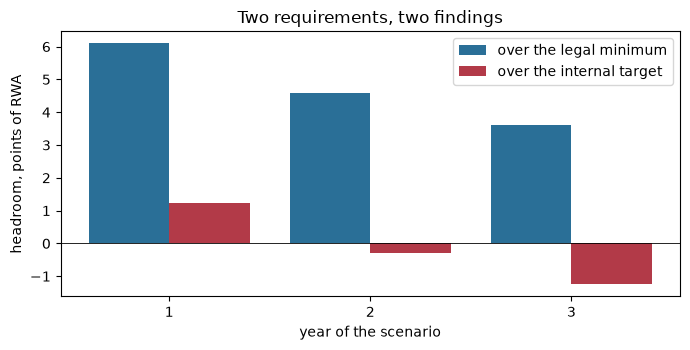

headroom over the legal minimum, points [6.1  4.59 3.62]
headroom over the internal target, points [ 1.22 -0.29 -1.25]


In [11]:
# The headroom of the stressed effective equity over the legal minimum and over the internal target
over_legal = [(y.pe_pct - legal_minimum) * 100 for y in stress]
over_target = [(y.pe_pct - oi.oi) * 100 for y in stress]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(np.arange(3) - 0.2, over_legal, width=0.4, color="#2a6f97", label="over the legal minimum")
ax.bar(np.arange(3) + 0.2, over_target, width=0.4, color="#b23a48", label="over the internal target")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xticks(np.arange(3))
ax.set_xticklabels(YEARS)
ax.set_xlabel("year of the scenario")
ax.set_ylabel("headroom, points of RWA")
ax.set_title("Two requirements, two findings")
ax.legend()
fig.tight_layout()
plt.show()
print("headroom over the legal minimum, points", np.round(over_legal, 2))
print("headroom over the internal target, points", np.round(over_target, 2))

The blue bars stay well above zero for the three years, 6.10, 4.59 and 3.62 points, while the red bars start at 1.22 and then
cross zero, to minus 0.29 and minus 1.25. The proxy for Pillar 2 guidance is zero, because the largest fall of CET1 over RWA,
3.64 points, is smaller than the 4.0 points of usable buffers, so the case sets no guidance on top. The figure shows that the
answer to a stress test depends on which requirement it is read against; it does not say which of the two the supervisor
would act on, which is a question of the regulation and not of the arithmetic.

**Answer:** yes against the legal minimum and no against the bank's own target. Under the Federal Reserve severely adverse
scenario the effective-equity ratio of Banco Andino is 15.72, 14.21 and 13.25 percent in the three years, always above the legal
minimum of 9.625 percent, with a headroom of 6.10, 4.59 and 3.62 points and no deficit, but it is 1.22 points above the 14.5
percent internal target in year 1 and 0.29 and 1.25 points below it in years 2 and 3. The loss-only CET1 ratio falls from 11.00
to 9.83, 8.32 and 7.36 percent of RWA after stressed losses of CLP 87,706, 113,174 and 72,193 million, and the labelled PPNR row,
CLP 147,813 and 147,070 million a year, would lift it to 11.80, 12.25 and 13.25 percent. The 34 rows of the Annex 3 form rebuilt
with the engine are the committed ones.

What this notebook does not show: the NII behind the PPNR was read, not recomputed, because it needs the interest-rate book of
the case C15; the capital and RWA are anchors of a synthetic bank, so none of these ratios describes a real bank; and the
stressed loss is a floor, because market and operational risk carry only their expected loss in every scenario.

## Summary

- The headline CET1 path is the starting CET1 less the cumulated stressed losses, with no revenue invented; the PPNR is a labelled row on two stated ratios.
- The internal target OI adds the 8 percent minimum, the buffers, the bank's own Pillar 2 estimate and a voluntary buffer; the 4 percent cap binds the article 66 quinquies requirement, never the own estimate, and the engine refuses both mistakes.
- `capital_plan` runs base, stress and stress with mitigation on a static balance sheet; in the severely adverse scenario the legal minimum holds in every year and the internal target does not.
- The EBA static balance-sheet rules (constant total, nothing leaves stage 3) are applied by `eba_static_balance_sheet` and checked by a test that names a planted cure and a changed total.
- The P2G figure is a labelled Contraste approximation, and the 34 rows of Annex 3 rebuilt with the engine are identical to the committed ones.

**What to try next.** Change `c_d`, the voluntary buffer, to zero in step 3 and see how the internal target and its headroom move; then continue with notebook 06, which asks the reverse question: which scenario would take the bank to the legal minimum.

## References

- EBA (2025), 2025 EU-wide stress test, Methodological Note of 2025-01-20: the static balance sheet (paragraphs 24, 33, 34 and 90 to 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- CMF Chile (2025), Circular 2.365 and Annex 3 of the IAPE capital self-assessment, the 34-row summary form. https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- Dossier 03 of the persisted Contraste research (the Chilean capital stack in 2026, the internal capital target and the stress testing inside the IAPE), as summarised in the SDD's research basis.
- This repository: `docs/contracts/engine/stress-api.md` (the capital engine) and `docs/design/features/c18/design.md`.